# 12. 딥러닝 모델 템플릿

**AICE Associate 학습 12단계**

시험의 마지막 두 문항(13~14번)은 **tensorflow(keras)로 딥러닝 모델을 만들고 학습 곡선을 그리는 문제**입니다.
문항에는 **토폴로지 그림**(층 구성)과 가이드가 주어지고, 그대로 코드로 옮기면 됩니다.

### 학습 목표
1. `Sequential` 모델에 `Dense`, `Dropout`, `BatchNormalization` 층을 쌓을 수 있다.
2. 문제 유형(이진 분류 / 다중 분류 / 회귀)에 맞는 **출력층·activation·loss**를 고를 수 있다.
3. `compile` → `fit`(EarlyStopping, ModelCheckpoint) → `evaluate` → `predict` 흐름을 익힌다.
4. `history`로 학습 곡선을 그리고 과적합을 판단할 수 있다.

### ★ 가장 중요한 표: 문제 유형별 설정

| 문제 유형 | 출력층 | activation | loss | y 형태 |
|---|---|---|---|---|
| 이진 분류 (출력 1개) | `Dense(1)` | `sigmoid` | `binary_crossentropy` | 0/1 |
| 이진 분류 (출력 2개) | `Dense(2)` | `sigmoid` 또는 `softmax` | `binary_crossentropy` 또는 `categorical_crossentropy` | `to_categorical`로 원-핫 |
| 다중 분류 (원-핫 y) | `Dense(클래스 수)` | `softmax` | `categorical_crossentropy` | `to_categorical`로 원-핫 |
| 다중 분류 (정수 y) | `Dense(클래스 수)` | `softmax` | `sparse_categorical_crossentropy` | 0,1,2,... |
| 회귀 | `Dense(1)` | `linear` (또는 생략) | `mse` / `mean_squared_error` | 숫자 |

> 샘플 문항(분류)에서는 **`Dense(2, activation='sigmoid')` + `binary_crossentropy` + `to_categorical`** 조합이 나왔습니다. 가이드에 적힌 그대로 쓰세요.

In [1]:
import platform
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.font_manager as fm
import warnings
warnings.filterwarnings('ignore')

# OS에 따라서 한글 폰트 로드
os_name = platform.system()

if os_name == 'Linux':
    font_names = [f.name for f in fm.fontManager.ttflist]
    for cand in ['NanumGothicCoding', 'NanumGothic', 'Noto Sans CJK KR', 'Noto Sans CJK JP']:
        if cand in font_names:
            plt.rc('font', family=cand)
            break
    print("(리눅스) 한글폰트 로드 완료")
elif os_name == 'Windows':
    font_path = 'C:\\Windows\\Fonts\\malgun.ttf'
    font = fm.FontProperties(fname=font_path).get_name()
    mpl.rc('font', family=font)
    print("(윈도우) 한글폰트 로드 완료")
elif os_name == 'Darwin':
    plt.rc('font', family='AppleGothic')
    print("(맥) 한글폰트 로드 완료")
else:
    print(f"알 수 없는 OS입니다: {os_name}")

# 마이너스 기호 깨짐 방지
mpl.rcParams['axes.unicode_minus'] = False

(리눅스) 한글폰트 로드 완료


> **딥러닝 모델을 구현하기 위해 <span style="color:red">아래 함수를 불러오는 코드를 실행하세요.</span>** (시험에서 제공되는 셀)

In [2]:
import tensorflow as tf
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Dense, Activation, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.utils import to_categorical

tf.random.set_seed(1)

---
# Part 1. 이진 분류 — Titanic 생존 예측

## 1. 데이터 준비 (10번 템플릿과 동일)

In [3]:
df = pd.read_csv('titanic.csv')
data = df.drop(['PassengerId', 'Name', 'Ticket', 'Cabin'], axis=1)
data['Age'] = data['Age'].fillna(data['Age'].median())
data['Embarked'] = data['Embarked'].fillna(data['Embarked'].mode()[0])
data = pd.get_dummies(data=data, columns=['Sex', 'Embarked'], drop_first=True, dtype=int)

X = data.drop('Survived', axis=1)
y = data['Survived']

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 딥러닝은 스케일링이 사실상 필수
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_valid = scaler.transform(X_valid)
print(X_train.shape, X_valid.shape)

(712, 8) (179, 8)


## 2. 모델 구성: `Sequential`

### 토폴로지 예시 (시험에서는 그림으로 주어짐)
```
Input (8)  →  Dense(64, relu)  →  Dropout(0.3)  →  Dense(32, relu)  →  Dense(16, relu)  →  Dense(1, sigmoid)
```

| 층 | 역할 |
|---|---|
| `Dense(유닛수, activation=...)` | 완전연결층. **첫 층에만** `input_dim=피처수` 또는 `input_shape=(피처수,)` |
| `Dropout(비율)` | 학습 중 일부 뉴런을 무작위로 끔 → 과적합 방지 |
| `BatchNormalization()` | 층의 출력을 정규화 → 학습 안정화 |

In [4]:
# 방법 1: add로 한 층씩
model = Sequential()
model.add(Dense(64, activation='relu', input_dim=X_train.shape[1]))
model.add(Dropout(0.3))
model.add(Dense(32, activation='relu'))
model.add(Dense(16, activation='relu'))
model.add(Dense(1, activation='sigmoid'))

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,201 (12.50 KB)

 Trainable params: 3,201 (12.50 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
# 방법 2: 리스트로 한 번에 (샘플 문항 분류편 13번 형태) - 결과는 같습니다
model2 = Sequential([
    Dense(64, activation='relu', input_dim=X_train.shape[1]),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dense(16, activation='relu'),
    Dense(1, activation='sigmoid')
])
print(len(model2.layers), "개 층")

5 개 층


> 📌 `model.summary()`의 **Param #** 계산: Dense 층 = (입력 수 × 유닛 수) + 유닛 수(bias)
> 예) 첫 층: 8 × 64 + 64 = 576

## 3. 컴파일: `compile`

```python
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
```

In [6]:
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

## 4. 학습: `fit` + 콜백

| 파라미터 | 의미 |
|---|---|
| `epochs` | 전체 데이터를 몇 번 반복 학습할지 |
| `batch_size` | 한 번에 학습하는 샘플 수 |
| `validation_data=(X_valid, y_valid)` | 매 epoch 마다 검증 성능 계산 → `val_` 지표 생성 |
| `callbacks=[...]` | EarlyStopping, ModelCheckpoint 등 |

**EarlyStopping**: `monitor`가 `patience` epoch 동안 개선되지 않으면 학습 중단
**ModelCheckpoint**: `monitor` 기준 가장 좋은 모델을 파일로 저장

In [7]:
estop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
mc = ModelCheckpoint('best_titanic.keras', monitor='val_loss', save_best_only=True, verbose=0)

history = model.fit(X_train, y_train,
                    epochs=100,
                    batch_size=32,
                    validation_data=(X_valid, y_valid),
                    callbacks=[estop, mc],
                    verbose=0)          # verbose=1 이면 epoch마다 진행 상황 출력
print("실제 학습한 epoch 수:", len(history.history['loss']))
print(history.history.keys())

실제 학습한 epoch 수: 32
dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])


## 5. ★ 학습 곡선 시각화 (시험 마지막 문항)

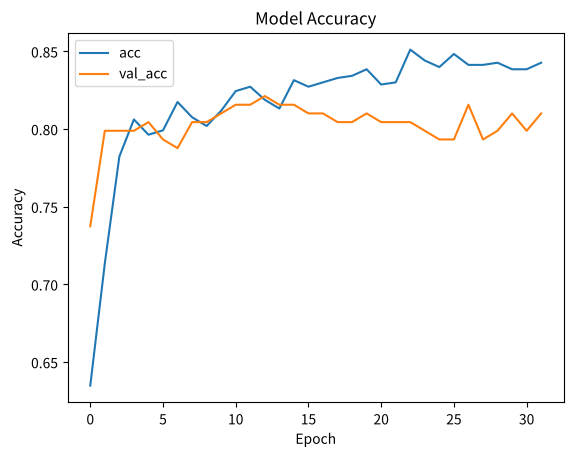

In [8]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['acc', 'val_acc'])
plt.show()

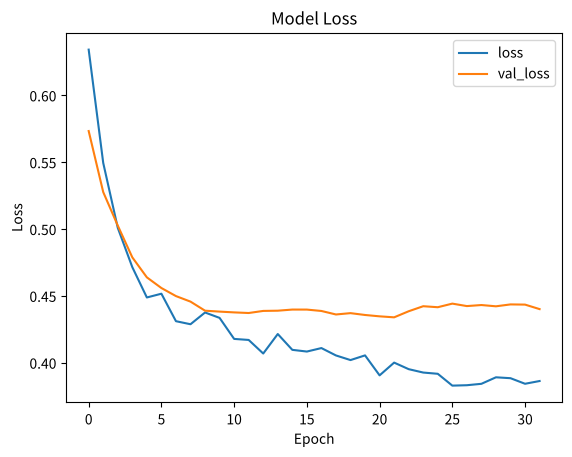

In [9]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(['loss', 'val_loss'])
plt.show()

## 6. 평가와 예측

In [10]:
loss, acc = model.evaluate(X_valid, y_valid, verbose=0)
print(f"검증 loss={loss:.4f}, accuracy={acc:.4f}")

검증 loss=0.4338, accuracy=0.8045


In [11]:
# predict 결과는 '1일 확률' → 0.5 기준으로 0/1 변환
proba = model.predict(X_valid, verbose=0)
print(proba[:5].ravel())
y_pred = (proba > 0.5).astype(int).ravel()

from sklearn.metrics import accuracy_score, classification_report
print(accuracy_score(y_valid, y_pred))
print(classification_report(y_valid, y_pred))

[0.1122238  0.05303597 0.19606732 0.06822946 0.8360739 ]
0.8044692737430168
              precision    recall  f1-score   support

           0       0.79      0.94      0.85       110
           1       0.85      0.59      0.70        69

    accuracy                           0.80       179
   macro avg       0.82      0.77      0.78       179
weighted avg       0.81      0.80      0.80       179



In [12]:
# 저장된 최적 모델 불러오기
best = load_model('best_titanic.keras')
print(best.evaluate(X_valid, y_valid, verbose=0))

[0.43384137749671936, 0.8044692873954773]


---
# Part 2. 출력 2개 분류 — `to_categorical` + `LabelEncoder` (샘플 문항 형태)

타깃이 문자열('Pass'/'Fail', 'Y'/'N')일 때 쓰는 방식입니다.
1. `LabelEncoder`로 문자열 → 정수 (0, 1)
2. `to_categorical`로 정수 → 원-핫 (`[1, 0]`, `[0, 1]`)
3. 출력층 `Dense(2, ...)`

In [13]:
from sklearn.preprocessing import LabelEncoder

y_str_train = np.where(y_train == 1, 'Survived', 'Dead')    # 문자열 타깃 예시
y_str_valid = np.where(y_valid == 1, 'Survived', 'Dead')

le = LabelEncoder()
y_train2 = le.fit_transform(y_str_train)
y_valid2 = le.transform(y_str_valid)
print(le.classes_, y_train2[:5])

y_train2 = to_categorical(y_train2)
y_valid2 = to_categorical(y_valid2)
print(y_train2[:3])

['Dead' 'Survived'] [1 0 0 1 1]
[[0. 1.]
 [1. 0.]
 [1. 0.]]


In [14]:
model_c = Sequential([
    Dense(128, activation='relu', input_dim=X_train.shape[1]),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(2, activation='sigmoid')
])
estop = EarlyStopping(monitor='val_loss', patience=14)
model_c.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
history_c = model_c.fit(X_train, y_train2, epochs=30, batch_size=128,
                        validation_data=(X_valid, y_valid2), callbacks=[estop], verbose=0)

# 원-핫 예측 결과 → argmax로 클래스 번호 → inverse_transform으로 원래 라벨
pred = np.argmax(model_c.predict(X_valid, verbose=0), axis=1)
print(le.inverse_transform(pred[:5]))
print("accuracy:", accuracy_score(np.argmax(y_valid2, axis=1), pred))

['Dead' 'Dead' 'Dead' 'Dead' 'Survived']
accuracy: 0.8324022346368715


---
# Part 3. 다중 분류 — softmax

Titanic의 객실 등급(Pclass: 1/2/3)을 예측하는 3-클래스 예제입니다.

In [15]:
mc_df = df.drop(['PassengerId', 'Name', 'Ticket', 'Cabin'], axis=1).dropna()
mc_df = pd.get_dummies(mc_df, columns=['Sex', 'Embarked'], drop_first=True, dtype=int)
Xm = mc_df.drop('Pclass', axis=1)
ym = mc_df['Pclass'] - 1          # 0, 1, 2 로 맞춤

Xm_train, Xm_valid, ym_train, ym_valid = train_test_split(Xm, ym, test_size=0.2, random_state=42, stratify=ym)
sc_m = StandardScaler()
Xm_train = sc_m.fit_transform(Xm_train)
Xm_valid = sc_m.transform(Xm_valid)

model_m = Sequential([
    Dense(64, activation='relu', input_shape=(Xm_train.shape[1],)),
    BatchNormalization(),
    Dense(32, activation='relu'),
    Dense(3, activation='softmax')       # 클래스 수만큼
])
# y가 정수(0,1,2) → sparse_categorical_crossentropy
model_m.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
h_m = model_m.fit(Xm_train, ym_train, epochs=40, batch_size=32, validation_data=(Xm_valid, ym_valid),
                  callbacks=[EarlyStopping(monitor='val_loss', patience=5)], verbose=0)
print("검증 accuracy:", model_m.evaluate(Xm_valid, ym_valid, verbose=0)[1])

검증 accuracy: 0.8391608595848083


---
# Part 4. 회귀 — 평균 청구 금액 예측 (샘플 문항 회귀편 형태)

In [16]:
cust = pd.read_csv('cust_data.csv')
reg = cust.drop(['A_bill', 'B_bill'], axis=1)
reg = pd.get_dummies(reg, columns=['class', 'sex', 'stop', 'npay', 'termination'], drop_first=True, dtype=int)
Xr = reg.drop('avg_bill', axis=1)
yr = reg['avg_bill']
Xr_train, Xr_valid, yr_train, yr_valid = train_test_split(Xr, yr, test_size=0.2, random_state=42)

from sklearn.preprocessing import RobustScaler
rs = RobustScaler()
Xr_train = rs.fit_transform(Xr_train)
Xr_valid = rs.transform(Xr_valid)

### 토폴로지
```
Input → Dense(64, selu) → Dropout(0.1) → Dense(32, selu) → Dense(16, selu) → Dense(1, linear)
```

In [17]:
model_r = Sequential()
model_r.add(Dense(64, activation='selu', input_dim=Xr_train.shape[1]))
model_r.add(Dropout(0.1))
model_r.add(Dense(32, activation='selu'))
model_r.add(Dense(16, activation='selu'))
model_r.add(Dense(1, activation='linear'))

estop = EarlyStopping(monitor='val_loss', patience=9)
model_r.compile(optimizer='adam', loss='mean_squared_error', metrics=['mse'])

history_r = model_r.fit(Xr_train, yr_train, batch_size=128, epochs=30,
                        validation_data=(Xr_valid, yr_valid), callbacks=[estop], verbose=0)

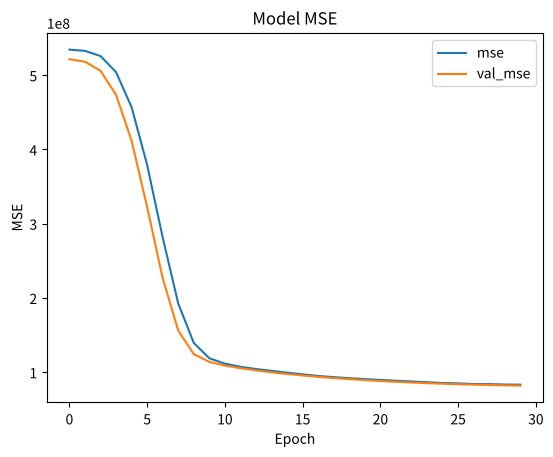

In [18]:
plt.plot(history_r.history['mse'])
plt.plot(history_r.history['val_mse'])
plt.title('Model MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.legend(['mse', 'val_mse'])
plt.show()

> 📌 금액처럼 **타깃 값이 크면** MSE도 매우 크게 나오고 30 epoch로는 덜 수렴할 수 있습니다.
> 시험에서는 가이드대로만 학습하면 되며, 성능 수치 자체는 채점 대상이 아닌 경우가 많습니다.

In [19]:
from sklearn.metrics import mean_absolute_error, r2_score
pr = model_r.predict(Xr_valid, verbose=0).ravel()
print("MAE:", mean_absolute_error(yr_valid, pr), " R2:", r2_score(yr_valid, pr))

MAE: 6955.902503248521  R2: 0.12356492162809518


---
## 📋 딥러닝 문항 체크리스트

- [ ] 첫 `Dense`에 `input_dim=X_train.shape[1]` (또는 `input_shape=(n,)`) 을 넣었는가?
- [ ] 토폴로지 그림의 **유닛 수, Dropout 비율, 층 순서**가 같은가?
- [ ] 히든층 activation (`relu`/`selu` 등)과 출력층 activation (`sigmoid`/`softmax`/`linear`)이 가이드와 같은가?
- [ ] 출력층 유닛 수: 이진(1 또는 2) / 다중(클래스 수) / 회귀(1)
- [ ] `EarlyStopping(monitor='val_loss', patience=N)` — **patience** 이름 기억!
- [ ] `compile(optimizer=..., loss=..., metrics=[...])` — metrics는 **리스트**
- [ ] `fit(X_train, y_train, epochs=..., batch_size=..., validation_data=(X_valid, y_valid), callbacks=[estop])`
- [ ] 학습 정보는 `history` 변수에 저장
- [ ] 학습 곡선: `history.history['키']`, `plt.title / xlabel / ylabel / legend`
- [ ] "안내된 내용 외 별도의 파라미터를 입력하지 마세요" → 시키지 않은 옵션은 넣지 않기